In [1]:
import pandas as pd

In [3]:
df = pd.read_csv('../../athlete_events.csv')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [53]:
"""
New columns:
-Athlete_Medal_Count: Count of medals by athlete (ID needed because of possibility of duplicate names)
-Athlete_OneGame_Medal_Count: Count of medals by athlete for a single Games

-Gold_Medal_Flag: Indicates Gold Medal or not
-Silver_Medal_Flag: Indicates Silver Medal or not
-Bronze_Medal_Flag: Indicates Bronze Medal or not
"""

df['Athlete_Medal_Count'] = df.groupby(['ID','Name'])['Medal'].transform('count')
df['Athlete_OneGame_Medal_Count'] = df.groupby(['ID','Name','Games'])['Medal'].transform('count')

df['Gold_Medal_Flag'] = df['Medal'].map({'Gold': 'Gold'})
df['Athlete_OneGame_GoldMedal_Count'] = df.groupby(['ID','Name','Games'])['Gold_Medal_Flag'].transform('count')
df['Silver_Medal_Flag'] = df['Medal'].map({'Silver': 'Silver'})
df['Athlete_OneGame_SilverMedal_Count'] = df.groupby(['ID','Name','Games'])['Silver_Medal_Flag'].transform('count')
df['Bronze_Medal_Flag'] = df['Medal'].map({'Bronze': 'Bronze'})
df['Athlete_OneGame_BronzeMedal_Count'] = df.groupby(['ID','Name','Games'])['Bronze_Medal_Flag'].transform('count')

In [6]:
#Excluding Sport to account for multi-sport athletes
#Adding Sex for medals by gender
athlete_medal_counts_overall = df.loc[:, ['Name', 'Sex', 'Season', 'Athlete_Medal_Count']].drop_duplicates().sort_values(by='Athlete_Medal_Count', ascending=False)
athlete_medal_counts_overall.head(10)

,Name,Sex,Season,Athlete_Medal_Count
187887,"Michael Fred Phelps, II",M,Summer,28
133184,Larysa Semenivna Latynina (Diriy-),F,Summer,18
7510,Nikolay Yefimovich Andrianov,M,Summer,15
177408,Takashi Ono,M,Summer,13
22698,Ole Einar Bjrndalen,M,Winter,13
148317,Edoardo Mangiarotti,M,Summer,13
217312,Borys Anfiyanovych Shakhlin,M,Summer,13
173959,Paavo Johannes Nurmi,M,Summer,12
239223,"Jennifer Elisabeth ""Jenny"" Thompson (-Cumpelik)",F,Summer,12
69801,Birgit Fischer-Schmidt,F,Summer,12


In [10]:
#Check if athletes with same name are aggregated (they are not)
athlete_medal_counts_overall.describe(include='object')

,Name,Sex,Season
count,135281,135281,135281
unique,134732,2,2
top,Chen Jing,M,Summer
freq,4,101346,116347


In [11]:
#athlete_medal_counts_overall[athlete_medal_counts_overall.Name=='Takashi Ono']
athlete_medal_counts_overall[athlete_medal_counts_overall.Name=='Chen Jing']

,Name,Sex,Season,Athlete_Medal_Count
39296,Chen Jing,F,Summer,4
39305,Chen Jing,F,Summer,1
39303,Chen Jing,F,Winter,0
39302,Chen Jing,M,Summer,0


In [15]:
df.loc[:, ['Name', 'Sex', 'Age', 'NOC', 'Games', 'Sport', 'Athlete_Medal_Count']][df.Name=='Chen Jing'].drop_duplicates()

,Name,Sex,Age,NOC,Games,Sport,Athlete_Medal_Count
39296,Chen Jing,F,19.0,CHN,1988 Summer,Table Tennis,4
39298,Chen Jing,F,27.0,TPE,1996 Summer,Table Tennis,4
39300,Chen Jing,F,31.0,TPE,2000 Summer,Table Tennis,4
39302,Chen Jing,M,20.0,CHN,1996 Summer,Athletics,0
39303,Chen Jing,F,26.0,CHN,1998 Winter,Ice Hockey,0
39304,Chen Jing,F,30.0,CHN,2002 Winter,Ice Hockey,0
39305,Chen Jing,F,25.0,CHN,2000 Summer,Volleyball,1
39306,Chen Jing,F,28.0,CHN,2004 Summer,Volleyball,1


<AxesSubplot:xlabel='Name'>

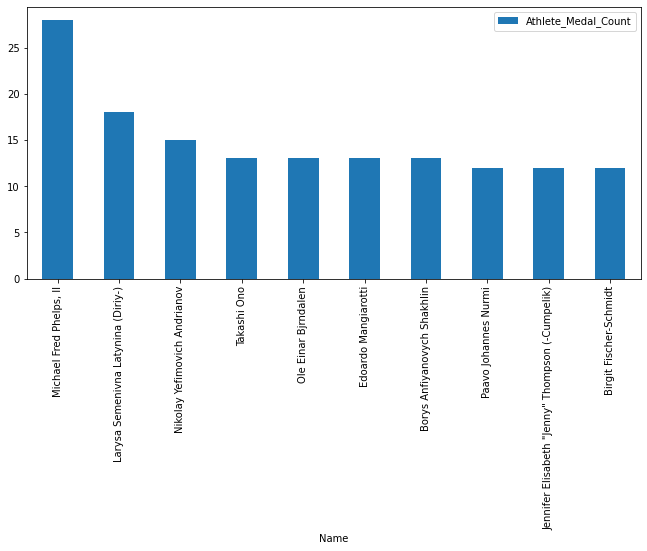

In [17]:
athlete_medal_counts_overall.head(10).plot.bar(x='Name', figsize=(11,5))

<AxesSubplot:ylabel='Name'>

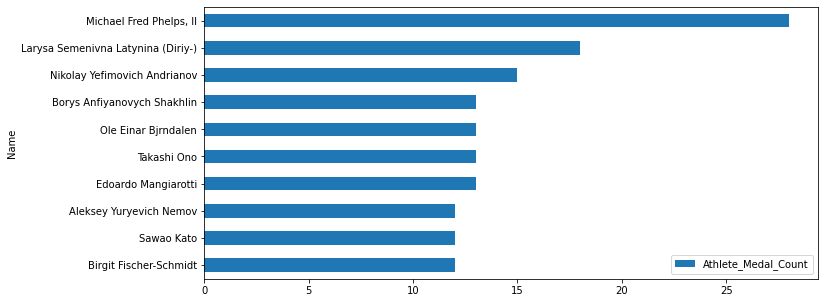

In [25]:
athlete_medal_counts_overall_h = df.loc[:, ['Name', 'Sex', 'Season', 'Athlete_Medal_Count']].drop_duplicates().sort_values(by='Athlete_Medal_Count')
athlete_medal_counts_overall_h.tail(10).plot.barh(x='Name', figsize=(11,5))

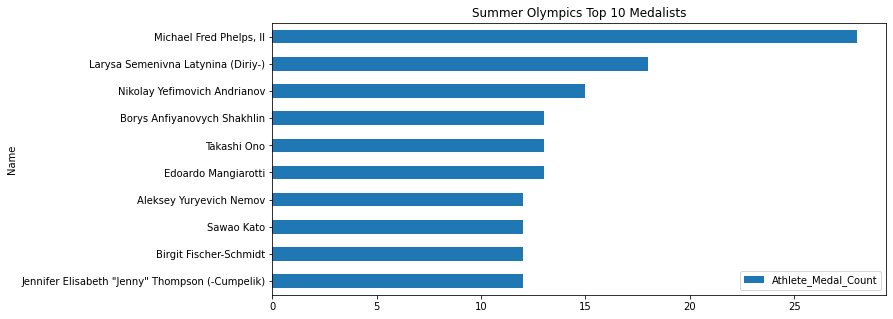

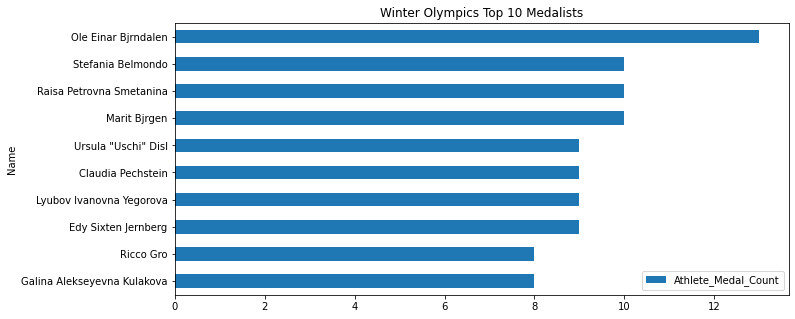

In [46]:
#Print summer and winter top 10s
for season in athlete_medal_counts_overall_h['Season'].unique():
    medal_counts = athlete_medal_counts_overall_h[athlete_medal_counts_overall_h.Season==season]
    medal_counts.tail(10).plot.barh(x='Name', figsize=(11,5), title=season + ' Olympics Top 10 Medalists')
    #medal_counts.tail(10).sort_values(by='Athlete_Medal_Count', ascending=False)

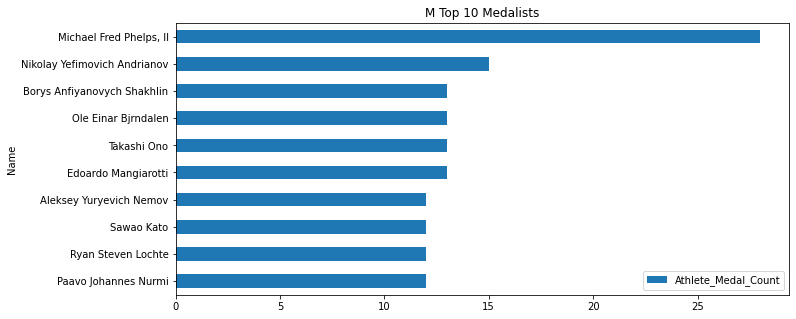

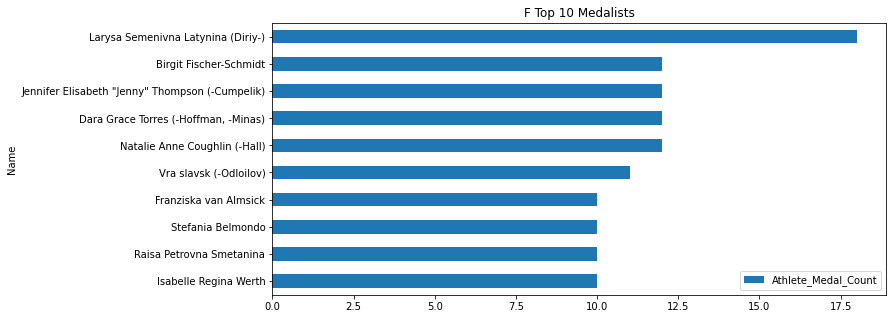

In [47]:
#Print male and female top 10s
for gender in athlete_medal_counts_overall_h['Sex'].unique():
    medal_counts = athlete_medal_counts_overall_h[athlete_medal_counts_overall_h.Sex==gender]
    medal_counts.tail(10).plot.barh(x='Name', figsize=(11,5), title=gender + ' Top 10 Medalists')

In [ ]:
#Analyze number of medals an athlete earns in one Games

In [48]:
df[df.Athlete_OneGame_Medal_Count>5].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'Athlete_OneGame_Medal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_Medal_Count', ascending=False)

,Name,Sex,Sport,Games,Athlete_OneGame_Medal_Count
187888,"Michael Fred Phelps, II",M,Swimming,2004 Summer,8
56199,Aleksandr Nikolayevich Dityatin,M,Gymnastics,1980 Summer,8
187896,"Michael Fred Phelps, II",M,Swimming,2008 Summer,8
7518,Nikolay Yefimovich Andrianov,M,Gymnastics,1976 Summer,7
217320,Borys Anfiyanovych Shakhlin,M,Gymnastics,1960 Summer,7
22090,"Matthew Nicholas ""Matt"" Biondi",M,Swimming,1988 Summer,7
135507,"Willis Augustus Lee, Jr.",M,Shooting,1920 Summer,7
98812,Mariya Kindrativna Horokhovska,F,Gymnastics,1952 Summer,7
226662,Mark Andrew Spitz,M,Swimming,1972 Summer,7
226726,Lloyd Spencer Spooner,M,Shooting,1920 Summer,7


In [49]:
df[df.Athlete_OneGame_GoldMedal_Count>4].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_GoldMedal_Count', ascending=False)

,Name,Sex,Sport,Games,Athlete_OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",M,Swimming,2008 Summer,8
226662,Mark Andrew Spitz,M,Swimming,1972 Summer,7
179153,Kristin Otto,F,Swimming,1988 Summer,6
187888,"Michael Fred Phelps, II",M,Swimming,2004 Summer,6
217832,Vitaly Venediktovich Shcherbo,M,Gymnastics,1992 Summer,6
22090,"Matthew Nicholas ""Matt"" Biondi",M,Swimming,1988 Summer,5
93166,Anton Heida,M,Gymnastics,1904 Summer,5
93199,Eric Arthur Heiden,M,Speed Skating,1980 Winter,5
135507,"Willis Augustus Lee, Jr.",M,Shooting,1920 Summer,5
167263,Nedo Nadi,M,Fencing,1920 Summer,5


In [50]:
df[(df.Sex=='F') & (df.Athlete_OneGame_GoldMedal_Count>3)].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_GoldMedal_Count', ascending=False)

,Name,Sex,Sport,Games,Athlete_OneGame_GoldMedal_Count
179153,Kristin Otto,F,Swimming,1988 Summer,6
21758,Simone Arianne Biles,F,Gymnastics,2016 Summer,4
23132,"Francina Elsje ""Fanny"" Blankers-Koen",F,Athletics,1948 Summer,4
36625,Vra slavsk (-Odloilov),F,Gymnastics,1968 Summer,4
63527,"Kornelia Ender (-Matthes, -Grummt)",F,Swimming,1976 Summer,4
72307,"Melissa Jeanette ""Missy"" Franklin",F,Swimming,2012 Summer,4
115446,gnes Keleti-Srkny (Klein),F,Gymnastics,1956 Summer,4
133184,Larysa Semenivna Latynina (Diriy-),F,Gymnastics,1956 Summer,4
134632,"Kathleen Genevieve ""Katie"" Ledecky",F,Swimming,2016 Summer,4
222312,Lidiya Pavlovna Skoblikova (-Polozkova),F,Speed Skating,1964 Winter,4


In [51]:
df[(df.Sex=='M') & (df.Athlete_OneGame_GoldMedal_Count>3)].loc[:, ['Name', 'Sex', 'Games', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_GoldMedal_Count', ascending=False)
#removing sport b/c of multi-sport athletes at one games

,Name,Sex,Games,Athlete_OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",M,2008 Summer,8
226662,Mark Andrew Spitz,M,1972 Summer,7
217832,Vitaly Venediktovich Shcherbo,M,1992 Summer,6
187888,"Michael Fred Phelps, II",M,2004 Summer,6
187911,"Michael Fred Phelps, II",M,2016 Summer,5
167263,Nedo Nadi,M,1920 Summer,5
135507,"Willis Augustus Lee, Jr.",M,1920 Summer,5
173963,Paavo Johannes Nurmi,M,1924 Summer,5
93199,Eric Arthur Heiden,M,1980 Winter,5
93166,Anton Heida,M,1904 Summer,5


In [57]:
#next: do stacked plot of gold medal count and overall medal count, maybe add bronze and silver medal counts to create the stacks
stacked_medal_counts = df.loc[:, ['Name', 'Athlete_OneGame_GoldMedal_Count', 'Athlete_OneGame_SilverMedal_Count', 'Athlete_OneGame_BronzeMedal_Count', 'Athlete_OneGame_Medal_Count']].drop_duplicates().sort_values(by=['Athlete_OneGame_Medal_Count', 'Athlete_OneGame_GoldMedal_Count', 'Athlete_OneGame_SilverMedal_Count', 'Athlete_OneGame_BronzeMedal_Count'], ascending=False)
stacked_medal_counts[stacked_medal_counts.Athlete_OneGame_Medal_Count>6]

,Name,Athlete_OneGame_GoldMedal_Count,Athlete_OneGame_SilverMedal_Count,Athlete_OneGame_BronzeMedal_Count,Athlete_OneGame_Medal_Count
187896,"Michael Fred Phelps, II",8,0,0,8
187888,"Michael Fred Phelps, II",6,0,2,8
56199,Aleksandr Nikolayevich Dityatin,3,4,1,8
226662,Mark Andrew Spitz,7,0,0,7
22090,"Matthew Nicholas ""Matt"" Biondi",5,1,1,7
135507,"Willis Augustus Lee, Jr.",5,1,1,7
7518,Nikolay Yefimovich Andrianov,4,2,1,7
217320,Borys Anfiyanovych Shakhlin,4,2,1,7
226726,Lloyd Spencer Spooner,4,1,2,7
98812,Mariya Kindrativna Horokhovska,2,5,0,7


<AxesSubplot:xlabel='Name'>

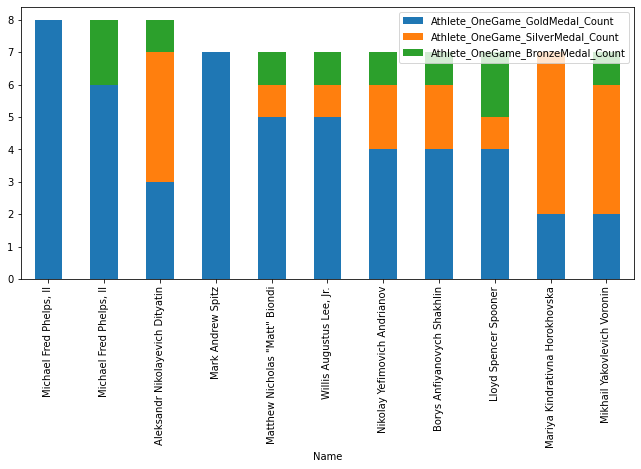

In [59]:
stacked_medal_counts[stacked_medal_counts.Athlete_OneGame_Medal_Count>6].plot.bar(x='Name', y=['Athlete_OneGame_GoldMedal_Count', 'Athlete_OneGame_SilverMedal_Count', 'Athlete_OneGame_BronzeMedal_Count'], stacked=True, figsize=(11,5))